In [ ]:
import vectorbt as vbt

# Here is how much profit we would have made if we invested $100 into Bitcoin
price = vbt.YFData.download(symbols=['BTC-USD'], start='2024-1-30', end='2024-11-04', auto_adjust=True).get('Close')

pf = vbt.Portfolio.from_holding(price, init_cash=100)
pf.total_profit()



In [ ]:
# Buy whenever 10-day SMA crosses above 50-day SMA and sell when opposite:

fast_ma = vbt.MA.run(price, 9)
slow_ma = vbt.MA.run(price, 20)
entries = fast_ma.ma_crossed_above(slow_ma)
exits = fast_ma.ma_crossed_below(slow_ma)
pf = vbt.Portfolio.from_signals(price, entries, exits, init_cash=100)

pf.total_profit()

In [ ]:
# Generate 1,000 strategies with random signals and test them on BTC and ETH:
import numpy as np

symbols = ["BTC-USD", "ETH-USD"]
price = vbt.YFData.download(symbols,  start='2024-1-30', end='2024-11-04', auto_adjust=True).get('Close')

n = np.random.randint(10, 101, size=1000).tolist()
pf = vbt.Portfolio.from_random_signals(price, n=n, init_cash=100, seed=42)

mean_expectancy = pf.trades.expectancy().groupby(['randnx_n', 'symbol']).mean()
fig = mean_expectancy.unstack().vbt.scatterplot(xaxis_title='randnx_n', yaxis_title='mean_expectancy')
fig.show()


In [ ]:
#For fans of hyperparameter optimization: here is a snippet for testing 10,000 window combinations of a dual SMA crossover strategy on BTC, USD, and LTC:

symbols = ["BTC-USD", "ETH-USD", "LTC-USD"]
price = vbt.YFData.download(symbols, start='2024-1-30', end='2024-11-04', auto_adjust=True).get('Close')
price.dropna(inplace=True)

windows = np.arange(2, 101)

fast_ma, slow_ma = vbt.MA.run_combs(price, window=windows, r=2, short_names=['fast', 'slow'])
entries = fast_ma.ma_crossed_above(slow_ma)
exits = fast_ma.ma_crossed_below(slow_ma)

pf_kwargs = dict(size=np.inf, fees=0.001, freq='1D')
pf = vbt.Portfolio.from_signals(price, entries, exits, **pf_kwargs)

fig = pf.total_return().vbt.heatmap(
    x_level='fast_window', y_level='slow_window', slider_level='symbol', symmetric=True,
    trace_kwargs=dict(colorbar=dict(title='Total return', tickformat='%')))
fig.show()

In [ ]:
# Digging into each strategy configuration is as simple as indexing with pandas:

pf[(10, 20, 'ETH-USD')].stats()


In [ ]:
pf[(10, 20, 'ETH-USD')].plot().show()


In [ ]:
# https://www.pyquantnews.com/the-pyquant-newsletter/1000000-backtest-simulations-20-seconds-vectorbt
# To avoid overfitting, pros use a technique called walk-forward optimization.

# Walk-forward optimization is a technique used to find the best settings for a trading strategy.

import numpy as np
import scipy.stats as stats

import vectorbt as vbt

windows = np.arange(10, 50)

price = vbt.YFData.download('SOL-USD').get('Close')

'''
This function builds two moving averages for each window you pass in.

Then it creates DataFrames showing where the fast-moving average crosses above the slow-moving average. These are the trade entries. It does the opposite for the trade exits.

After the backtest is run, the function returns the Sharpe ratio.
'''

def simulate_all_params(price, windows, **kwargs):
    fast_ma, slow_ma = vbt.MA.run_combs(
        price, windows, r=2, short_names=["fast", "slow"]
    )
    entries = fast_ma.ma_crossed_above(slow_ma)
    exits = fast_ma.ma_crossed_below(slow_ma)

    pf = vbt.Portfolio.from_signals(price, entries, exits, **kwargs)
    return pf.sharpe_ratio()

'''
Next, you need to figure out the combination of windows that maximizes the Sharpe ratio.

The first function returns the indexes in the DataFrame for the windows in each data split that maximizes the Sharpe ratio. The second function returns the window values.

'''
def get_best_index(performance, higher_better=True):
    if higher_better:
        return performance[performance.groupby('split_idx').idxmax()].index
    return performance[performance.groupby('split_idx').idxmin()].index


def get_best_params(best_index, level_name):
    return best_index.get_level_values(level_name).to_numpy()

# Finally, create a function that runs the backtest with the windows that maximize the Sharpe ratio.

def simulate_best_params(price, best_fast_windows, best_slow_windows, **kwargs):

    fast_ma = vbt.MA.run(price, window=best_fast_windows, per_column=True)
    slow_ma = vbt.MA.run(price, window=best_slow_windows, per_column=True)

    entries = fast_ma.ma_crossed_above(slow_ma)
    exits = fast_ma.ma_crossed_below(slow_ma)

    pf = vbt.Portfolio.from_signals(price, entries, exits, **kwargs)
    return pf.sharpe_ratio()

# This code segments the prices into 30 splits, each two years long, and reserves 180 days for the test.

(in_price, in_indexes), (out_price, out_indexes) = price.vbt.rolling_split(
    n=30,
    window_len=365*2,
    set_lens=(180,),
    left_to_right=False,
)

in_sharpe = simulate_all_params(
    in_price,
    windows,
    direction="both",
    freq="d"
)


in_best_index = get_best_index(in_sharpe)

in_best_fast_windows = get_best_params(
    in_best_index,
    'fast_window'
)
in_best_slow_windows = get_best_params(
    in_best_index,
    'slow_window'
)
in_best_window_pairs = np.array(
    list(
        zip(
            in_best_fast_windows,
            in_best_slow_windows
        )
    )
)

out_test_sharpe = simulate_best_params(
    out_price,
    in_best_fast_windows,
    in_best_slow_windows,
    direction="both",
    freq="d"
)

in_sample_best = in_sharpe[in_best_index].values
out_sample_test = out_test_sharpe.values

print(in_sample_best, out_sample_test)

t, p = stats.ttest_ind(
    a=out_sample_test,
    b=in_sample_best,
    alternative="greater"
)
print (t,p)

'''
In this case, the p-value is close to 1 which means you cannot reject the null hypothesis that the out-of-sample Sharpe ratios are greater than the in-sample Sharpe ratios.

In other words, you are overfitted to noise.

The moving crossover is a toy example that is known not to make money. But the technique of optimizing parameters using walk-forward optimization is the state-of-the-art way of removing as much bias as possible.

And vector bt is the state-of-the-art backtesting library that makes it possible.
'''


[*********************100%***********************]  1 of 1 completed


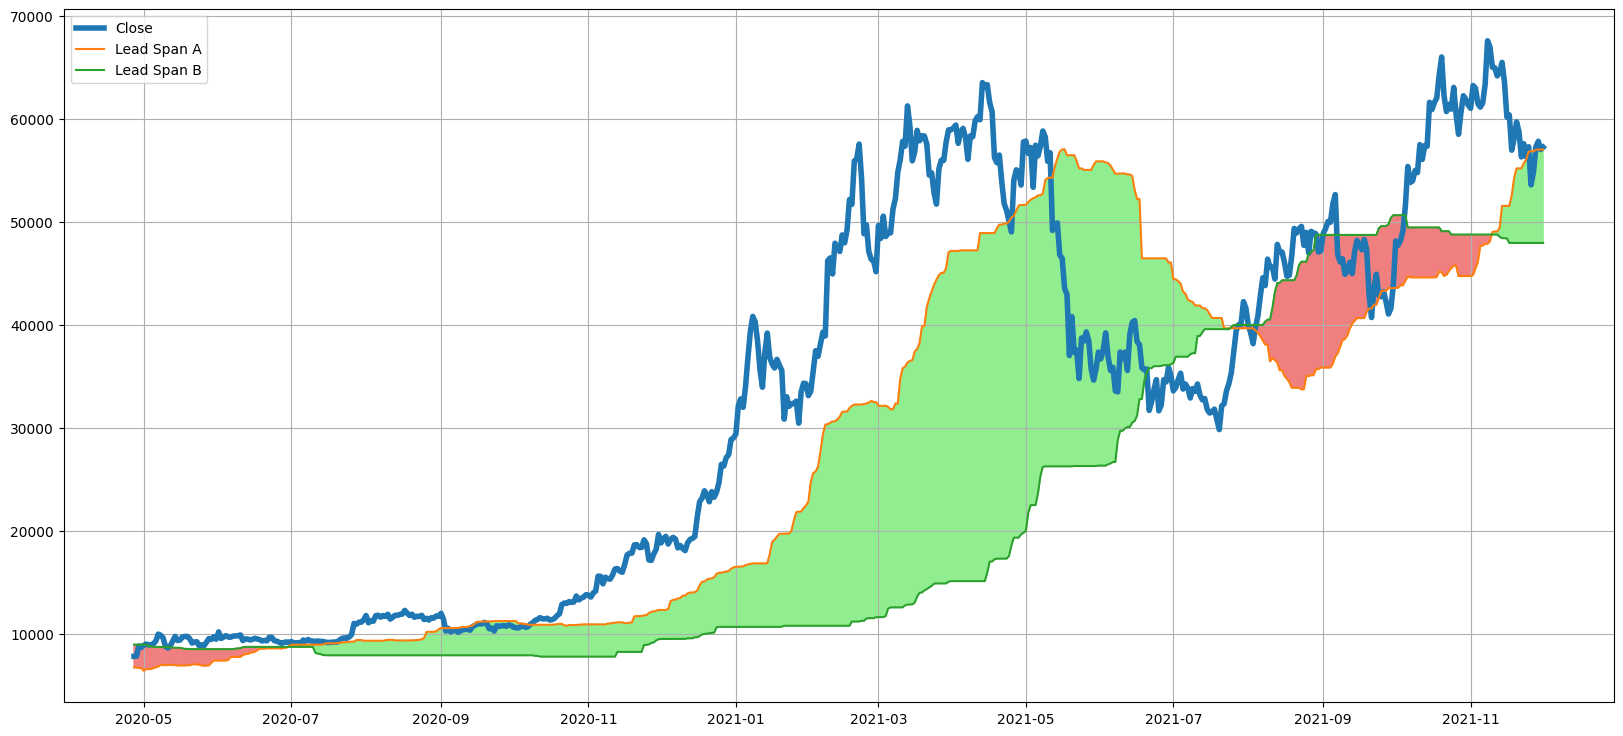

In [7]:
# Import packages
# The Ichimoku Cloud and Trading Strategy
# https://blog.quantinsti.com/ichimoku-cloud-trading-strategy/

import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Read BTC/USD data
df = yf.download('BTC-USD','2019-09-01', '2022-01-01')


# Define length of Tenkan Sen or Conversion Line
cl_period = 20

# Define length of Kijun Sen or Base Line
bl_period = 60

# Define length of Senkou Sen B or Leading Span B
lead_span_b_period = 120

# Define length of Chikou Span or Lagging Span
lag_span_period = 30

# Calculate conversion line
high_20 = df['High'].rolling(cl_period).max()
low_20 = df['Low'].rolling(cl_period).min()
df['conversion_line'] = (high_20 + low_20) / 2

# Calculate based line
high_60 = df['High'].rolling(bl_period).max()
low_60 = df['Low'].rolling(bl_period).min()
df['base_line'] = (high_60 + low_60) / 2

# Calculate leading span A
df['lead_span_A'] = ((df.conversion_line + df.base_line) / 2).shift(lag_span_period)

# Calculate leading span B
high_120 = df['High'].rolling(120).max()
low_120 = df['High'].rolling(120).min()
df['lead_span_B'] = ((high_120 + low_120) / 2).shift(lead_span_b_period)

# Calculate lagging span
df['lagging_span'] = df['Close'].shift(-lag_span_period)

# Drop NA values from Dataframe
df.dropna(inplace=True)

# Add figure and axis objects
fig, ax = plt.subplots(1, 1, sharex=True, figsize=(20, 9))

# Plot Close with index on x-axis with a line thickness of 4
ax.plot(df.index, df['Close'], linewidth=4, label='Close')

# Plot Leading Span A with index on the shared x-axis
ax.plot(df.index, df['lead_span_A'], label='Lead Span A')

# Plot Leading Span B with index on the sahred x-axis
ax.plot(df.index, df['lead_span_B'], label='Lead Span B')

# Use the fill_between of ax object to specify where to fill
ax.fill_between(df.index, df['lead_span_A'], df['lead_span_B'],
                where=df['lead_span_A'] >= df['lead_span_B'], color='lightgreen')

ax.fill_between(df.index, df['lead_span_A'], df['lead_span_B'],
                where=df['lead_span_A'] < df['lead_span_B'], color='lightcoral')

plt.legend(loc="best")
plt.grid()
plt.show()

[*********************100%***********************]  1 of 1 completed


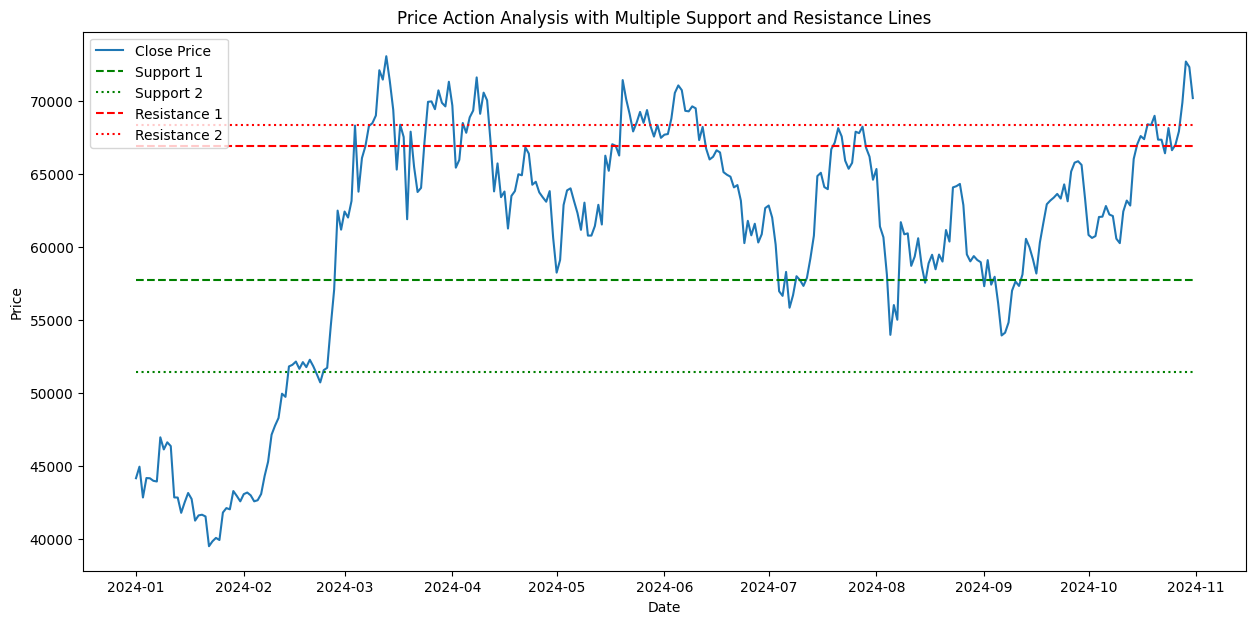

In [11]:
# Support and resistance for analysis
# Tools for price action analysis

import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Assuming you have your data in a DataFrame named 'data'
data = yf.download('BTC-USD','2024-01-01', '2024-11-01')

# Define additional support and resistance levels using your desired criteria
# Example: using 25th and 75th percentiles
support = data['Close'].quantile(0.25)
resistance = data['Close'].quantile(0.75)

support_2 = data['Close'].quantile(0.15)  # Optional: Add additional support levels
resistance_2 = data['Close'].quantile(0.85)  # Optional: Add additional resistance levels

# Plotting
plt.figure(figsize=(15, 7))

# Plotting Close Price
plt.plot(data['Close'], label='Close Price')

# Plotting Support Lines
plt.hlines(support, xmin=data.index[0], xmax=data.index[-1], colors='green', linestyles='dashed', label='Support 1')
plt.hlines(support_2, xmin=data.index[0], xmax=data.index[-1], colors='green', linestyles='dotted', label='Support 2')
# Add more support lines as needed using adjusted variable names

# Plotting Resistance Lines
plt.hlines(resistance, xmin=data.index[0], xmax=data.index[-1], colors='red', linestyles='dashed', label='Resistance 1')
plt.hlines(resistance_2, xmin=data.index[0], xmax=data.index[-1], colors='red', linestyles='dotted', label='Resistance 2')
# Add more resistance lines as needed using adjusted variable names

# Displaying Legends
plt.legend()

# Add labels and title
plt.title('Price Action Analysis with Multiple Support and Resistance Lines')
plt.xlabel('Date')
plt.ylabel('Price')
plt.show()

In [ ]:
import mongodb_util
import pandas as pd

db = mongodb_util.MongodbUtil()
db.test_mongodb_setup()
# Fetch data from MongoDB
data = db.util_fetch_all_collection('candles_ts_1d_BTC-USD')

# Convert data to a Pandas DataFrame
df = pd.DataFrame(list(data))
df.drop('_id', axis=1, inplace=True)
print(df.columns)
